### Task 1: Dataset Exploration and Understanding

In [2]:
# Copy a small, class-balanced subset of training images and their labels.
from pathlib import Path
import shutil
import pandas as pd

project_root = Path.cwd().resolve()
if not (project_root / "src").exists():
    project_root = project_root.parent

source_root = Path(
    r"C:\STUDY\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch"
)
target_root = project_root / "data"
target_root.mkdir(parents=True, exist_ok=True)

source_train_dir = source_root / "train" / "train"
target_train_dir = target_root / "train" / "train"
target_train_dir.mkdir(parents=True, exist_ok=True)

labels = pd.read_csv(source_root / "train_labels.csv")
subset = labels.groupby("class", group_keys=False).head(10).copy()
subset = subset[["image_id", "class"]].reset_index(drop=True)
subset["image_id"] = subset["image_id"].astype(int)

for _, row in subset.iterrows():
    image_id = row["image_id"]
    source_file = source_train_dir / f"{image_id:05d}.jpg"
    target_file = target_train_dir / f"{image_id:05d}.jpg"
    if source_file.exists():
        shutil.copy2(source_file, target_file)

subset.to_csv(target_root / "train_labels.csv", index=False)
print(f"Copied {len(subset)} training images to {target_train_dir}")
print(subset["class"].value_counts().sort_index().to_string())

# The test set is unlabeled, so copy the first 80 images (10 per class in the train subset).
source_test_dir = source_root / "test" / "test"
target_test_dir = target_root / "test" / "test"
target_test_dir.mkdir(parents=True, exist_ok=True)

test_files = sorted(path for path in source_test_dir.glob("*.jpg"))[: len(subset)]
for source_file in test_files:
    shutil.copy2(source_file, target_test_dir / source_file.name)
print(f"Copied {len(test_files)} test images to {target_test_dir}")

Copied 80 training images to C:\STUDY\kaggle-competition\data\train\train
class
CatEye      10
CatFace     10
CatMouth    10
CatNose     10
DogEye      10
DogFace     10
DogMouth    10
DogNose     10
Copied 80 test images to C:\STUDY\kaggle-competition\data\test\test


In [3]:
# Change this path later to use the full dataset.
dataset_root = project_root / "data"
train_dir = dataset_root / "train" / "train"
train_labels_path = dataset_root / "train_labels.csv"

In [4]:
# Inspect the training labels and check they match the image files.
train_labels = pd.read_csv(train_labels_path)

print(f"Shape: {train_labels.shape}")
print(f"Columns and dtypes:\n{train_labels.dtypes.to_string()}")
print(f"\nMissing values:\n{train_labels.isna().sum().to_string()}")
print(f"\nDuplicate image_ids: {train_labels['image_id'].duplicated().sum()}")

label_ids = {f"{image_id:05d}" for image_id in train_labels["image_id"]}
file_ids = {path.stem for path in train_dir.glob("*.jpg")}
print(f"Labels without an image file: {sorted(label_ids - file_ids)}")
print(f"Image files without a label: {sorted(file_ids - label_ids)}")

print(f"\nUnique classes ({train_labels['class'].nunique()}): {sorted(train_labels['class'].unique())}")
print("\nFirst rows:")
print(train_labels.head().to_string(index=False))

Shape: (80, 2)
Columns and dtypes:
image_id    int64
class         str

Missing values:
image_id    0
class       0

Duplicate image_ids: 0
Labels without an image file: []
Image files without a label: []

Unique classes (8): ['CatEye', 'CatFace', 'CatMouth', 'CatNose', 'DogEye', 'DogFace', 'DogMouth', 'DogNose']

First rows:
 image_id    class
        1   DogEye
        2 DogMouth
        3  DogFace
        4  DogNose
        5  DogNose


In [5]:
# Report the number of images in each class.
import pandas as pd

print(f"Training directory: {train_dir}")
if train_dir.exists():
    image_files = sorted(path for path in train_dir.iterdir() if path.is_file())
    print(f"  Image count: {len(image_files)}")
    print(f"  Sample files: {[path.name for path in image_files[:5]]}")
    print(f"  File extensions: {sorted({path.suffix.lower() for path in image_files})}")
else:
    raise FileNotFoundError(f"Training image directory not found: {train_dir}")

dataset_labels = pd.read_csv(train_labels_path)
print(f"\nTraining labels shape: {dataset_labels.shape}")
print(f"Training label columns: {dataset_labels.columns.tolist()}")
print("Training examples per class:")
print(dataset_labels["class"].value_counts().sort_index().to_string())
print("\nTraining label samples:")
print(dataset_labels.head().to_string(index=False))

Training directory: C:\STUDY\kaggle-competition\data\train\train
  Image count: 80
  Sample files: ['00001.jpg', '00002.jpg', '00003.jpg', '00004.jpg', '00005.jpg']
  File extensions: ['.jpg']

Training labels shape: (80, 2)
Training label columns: ['image_id', 'class']
Training examples per class:
class
CatEye      10
CatFace     10
CatMouth    10
CatNose     10
DogEye      10
DogFace     10
DogMouth    10
DogNose     10

Training label samples:
 image_id    class
        1   DogEye
        2 DogMouth
        3  DogFace
        4  DogNose
        5  DogNose


In [6]:
# Report class imbalance in the training labels.
class_counts = dataset_labels["class"].value_counts().sort_index()
class_percentages = (class_counts / class_counts.sum() * 100).round(2)
imbalance_ratio = class_counts.max() / class_counts.min()

print(f"Classes: {len(class_counts)}")
print(f"Largest class: {class_counts.idxmax()} ({class_counts.max()} images)")
print(f"Smallest class: {class_counts.idxmin()} ({class_counts.min()} images)")
print(f"Imbalance ratio (largest / smallest): {imbalance_ratio:.2f}")
print(pd.DataFrame({"count": class_counts, "percent": class_percentages}).to_string())

if imbalance_ratio == 1:
    print("\nClasses are perfectly balanced.")
else:
    print("\nClasses are imbalanced; consider class weights or resampling.")

Classes: 8
Largest class: CatEye (10 images)
Smallest class: CatEye (10 images)
Imbalance ratio (largest / smallest): 1.00
          count  percent
class                   
CatEye       10     12.5
CatFace      10     12.5
CatMouth     10     12.5
CatNose      10     12.5
DogEye       10     12.5
DogFace      10     12.5
DogMouth     10     12.5
DogNose      10     12.5

Classes are perfectly balanced.


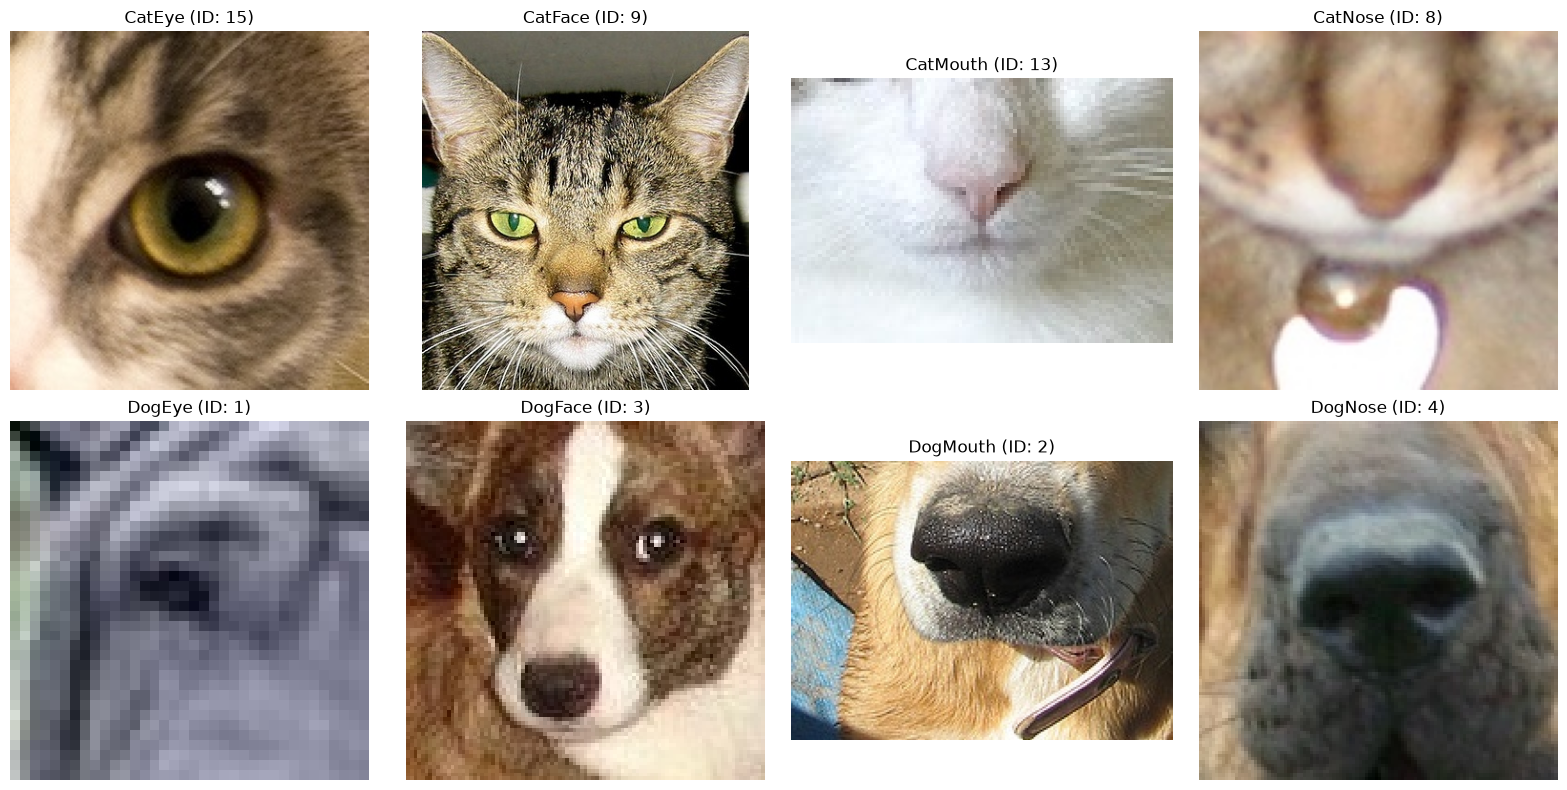

In [7]:
# Display one representative training image for each class.
from math import ceil
from PIL import Image
import matplotlib.pyplot as plt

representatives = dataset_labels.groupby("class", sort=True).first().reset_index()
num_images = len(representatives)
num_columns = min(4, num_images)
num_rows = ceil(num_images / num_columns)

fig, axes = plt.subplots(num_rows, num_columns, figsize=(4 * num_columns, 4 * num_rows))
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for ax, (_, sample) in zip(axes, representatives.iterrows()):
    image_path = train_dir / f"{int(sample['image_id']):05d}.jpg"
    if not image_path.is_file():
        raise FileNotFoundError(f"Image for class {sample['class']} not found: {image_path}")

    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(f"{sample['class']} (ID: {int(sample['image_id'])})")
    ax.axis("off")

for ax in axes[num_images:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
# Find training images whose dimensions differ from the most common size.
from collections import Counter
from PIL import Image

image_dimensions = {}
for image_path in sorted(train_dir.glob("*")):
    if image_path.is_file():
        with Image.open(image_path) as image:
            image_dimensions[image_path] = image.size

if not image_dimensions:
    raise ValueError(f"No images found in {train_dir}")

dimension_counts = Counter(image_dimensions.values())
common_size, common_count = dimension_counts.most_common(1)[0]
print(f"Checked {len(image_dimensions)} images.")
print("Image dimensions and counts:")
for dimensions, count in sorted(dimension_counts.items()):
    print(f"  {dimensions[0]}x{dimensions[1]}: {count}")

inconsistent_images = {
    image_path: dimensions
    for image_path, dimensions in image_dimensions.items()
    if dimensions != common_size
}
if inconsistent_images:
    print(f"\nFound {len(inconsistent_images)} images differing from the most common size ({common_size[0]}x{common_size[1]}):")
    for image_path, dimensions in inconsistent_images.items():
        print(f"  {image_path.name}: {dimensions[0]}x{dimensions[1]}")
else:
    print(f"\nAll images have the same size: {common_size[0]}x{common_size[1]}.")

Checked 80 images.
Image dimensions and counts:
  24x24: 2
  26x26: 1
  28x28: 1
  32x32: 1
  34x24: 1
  34x34: 2
  36x36: 3
  38x38: 2
  40x40: 1
  42x42: 2
  50x37: 1
  52x52: 1
  54x40: 1
  54x54: 1
  56x56: 1
  59x59: 1
  60x60: 1
  62x62: 1
  64x44: 1
  64x47: 1
  64x64: 1
  66x66: 1
  68x50: 1
  68x68: 2
  70x70: 1
  74x74: 1
  78x54: 1
  78x78: 2
  80x56: 1
  90x64: 1
  90x90: 1
  94x66: 1
  94x70: 1
  96x96: 1
  97x97: 1
  98x68: 1
  100x100: 1
  104x77: 1
  106x106: 1
  108x108: 1
  110x110: 1
  112x112: 1
  112x163: 1
  114x114: 1
  122x90: 1
  123x115: 1
  128x128: 1
  130x130: 1
  140x140: 1
  142x105: 1
  145x145: 1
  149x148: 1
  155x154: 1
  157x157: 1
  158x158: 1
  158x163: 1
  166x116: 1
  171x210: 1
  176x124: 1
  182x135: 1
  188x182: 1
  191x191: 1
  207x232: 1
  208x208: 1
  214x157: 1
  250x358: 1
  256x288: 1
  266x266: 1
  316x222: 1
  343x376: 1
  387x388: 1
  478x585: 1

Found 77 images differing from the most common size (36x36):
  00002.jpg: 214x157
  00003

In [9]:
# Find potentially blurry training images using Laplacian variance.
import numpy as np
from PIL import Image
from scipy.ndimage import laplace

# Lower scores indicate less visible detail; tune this threshold for the dataset.
blur_threshold = 50.0
blur_scores = {}

for image_path in sorted(train_dir.glob("*")):
    if image_path.is_file():
        with Image.open(image_path) as image:
            grayscale = image.convert("L").resize((128, 128))
            pixels = np.asarray(grayscale, dtype=np.float32)
        blur_scores[image_path] = float(laplace(pixels).var())

if not blur_scores:
    raise ValueError(f"No images found in {train_dir}")

blurry_images = {
    image_path: score
    for image_path, score in blur_scores.items()
    if score < blur_threshold
}
print(f"Checked {len(blur_scores)} images using a blur threshold of {blur_threshold:.1f}.")
if blurry_images:
    print(f"Potentially blurry images: {len(blurry_images)}")
    for image_path, score in sorted(blurry_images.items(), key=lambda item: item[1]):
        print(f"  {image_path.name}: sharpness score = {score:.2f}")
else:
    print("No images fell below the blur threshold.")

Checked 80 images using a blur threshold of 50.0.
Potentially blurry images: 24
  00033.jpg: sharpness score = 2.67
  00086.jpg: sharpness score = 4.68
  00075.jpg: sharpness score = 6.04
  00072.jpg: sharpness score = 6.53
  00064.jpg: sharpness score = 8.05
  00036.jpg: sharpness score = 8.58
  00010.jpg: sharpness score = 10.25
  00052.jpg: sharpness score = 10.37
  00030.jpg: sharpness score = 10.79
  00066.jpg: sharpness score = 11.26
  00019.jpg: sharpness score = 12.37
  00001.jpg: sharpness score = 14.66
  00048.jpg: sharpness score = 17.82
  00005.jpg: sharpness score = 17.97
  00039.jpg: sharpness score = 19.60
  00006.jpg: sharpness score = 20.58
  00045.jpg: sharpness score = 22.41
  00055.jpg: sharpness score = 22.82
  00125.jpg: sharpness score = 23.37
  00038.jpg: sharpness score = 26.43
  00027.jpg: sharpness score = 29.85
  00026.jpg: sharpness score = 44.85
  00060.jpg: sharpness score = 47.67
  00109.jpg: sharpness score = 47.69


In [10]:
# Find corrupted or unreadable image files in the training folder.
from PIL import Image, UnidentifiedImageError

corrupted_files = {}
checked_files = [path for path in sorted(train_dir.glob("*")) if path.is_file()]

for image_path in checked_files:
    try:
        with Image.open(image_path) as image:
            image.verify()
        # verify() does not catch every problem, so fully decode the image as well.
        with Image.open(image_path) as image:
            image.load()
    except (UnidentifiedImageError, OSError, SyntaxError, ValueError) as error:
        corrupted_files[image_path] = f"{type(error).__name__}: {error}"

print(f"Checked {len(checked_files)} files in {train_dir}.")
if corrupted_files:
    print(f"Found {len(corrupted_files)} corrupted files:")
    for image_path, reason in corrupted_files.items():
        print(f"  {image_path.name}: {reason}")
else:
    print("No corrupted files found.")

Checked 80 files in C:\STUDY\kaggle-competition\data\train\train.
No corrupted files found.


In [11]:
# Find exact duplicate images by hashing file contents.
import hashlib
from collections import defaultdict

files_by_hash = defaultdict(list)
checked_files = [path for path in sorted(train_dir.glob("*")) if path.is_file()]

for image_path in checked_files:
    files_by_hash[hashlib.sha256(image_path.read_bytes()).hexdigest()].append(image_path)

duplicate_groups = [paths for paths in files_by_hash.values() if len(paths) > 1]

print(f"Checked {len(checked_files)} files in {train_dir}.")
if duplicate_groups:
    extra_copies = sum(len(paths) - 1 for paths in duplicate_groups)
    print(f"Found {len(duplicate_groups)} groups of duplicates ({extra_copies} redundant files):")
    for paths in duplicate_groups:
        print("  " + ", ".join(path.name for path in paths))
else:
    print("No duplicate images found.")

Checked 80 files in C:\STUDY\kaggle-competition\data\train\train.
No duplicate images found.


In [12]:
# Create a stratified 80/20 train/validation split.
from sklearn.model_selection import train_test_split

train_labels, validation_labels = train_test_split(
    dataset_labels,
    test_size=0.2,
    random_state=42,
    stratify=dataset_labels["class"],
)
print(f"\nTraining split: {len(train_labels)} samples")
print(f"Validation split: {len(validation_labels)} samples")
print("Training split examples per class:")
print(train_labels["class"].value_counts().sort_index().to_string())
print("\nValidation split examples per class:")
print(validation_labels["class"].value_counts().sort_index().to_string())


Training split: 64 samples
Validation split: 16 samples
Training split examples per class:
class
CatEye      8
CatFace     8
CatMouth    8
CatNose     8
DogEye      8
DogFace     8
DogMouth    8
DogNose     8

Validation split examples per class:
class
CatEye      2
CatFace     2
CatMouth    2
CatNose     2
DogEye      2
DogFace     2
DogMouth    2
DogNose     2


In [13]:
# Compare class balance in the training and validation splits.
all_classes = dataset_labels["class"].dropna().unique()
if len(all_classes) == 0:
    raise ValueError("No class labels were found in the dataset.")

for split_name, split_labels in (("Training", train_labels), ("Validation", validation_labels)):
    class_counts = split_labels["class"].value_counts().reindex(all_classes, fill_value=0).sort_index()
    if class_counts.sum() == 0:
        raise ValueError(f"No class labels were found in the {split_name.lower()} split.")

    class_percentages = (class_counts / class_counts.sum() * 100).round(2)
    print(f"{split_name} samples per class:")
    print(class_counts.to_string())
    print(f"\n{split_name} percentage per class:")
    print(class_percentages.astype(str).add("%").to_string())

    if class_counts.min() == 0:
        print(f"\n{split_name} split is imbalanced: at least one class has no samples.")
    elif class_counts.nunique() == 1:
        print(f"\n{split_name} split is balanced: every class has the same number of samples.")
    else:
        imbalance_ratio = class_counts.max() / class_counts.min()
        print(f"\n{split_name} split is imbalanced.")
        print(f"Largest-to-smallest class ratio: {imbalance_ratio:.2f}:1")
    print()

Training samples per class:
class
CatEye      8
CatFace     8
CatMouth    8
CatNose     8
DogEye      8
DogFace     8
DogMouth    8
DogNose     8

Training percentage per class:
class
CatEye      12.5%
CatFace     12.5%
CatMouth    12.5%
CatNose     12.5%
DogEye      12.5%
DogFace     12.5%
DogMouth    12.5%
DogNose     12.5%

Training split is balanced: every class has the same number of samples.

Validation samples per class:
class
CatEye      2
CatFace     2
CatMouth    2
CatNose     2
DogEye      2
DogFace     2
DogMouth    2
DogNose     2

Validation percentage per class:
class
CatEye      12.5%
CatFace     12.5%
CatMouth    12.5%
CatNose     12.5%
DogEye      12.5%
DogFace     12.5%
DogMouth    12.5%
DogNose     12.5%

Validation split is balanced: every class has the same number of samples.

